# Cookie Cats A/B 테스트: 게이트 위치 변경과 리텐션

**분석 목적:** 첫 게이트를 Level 30에서 Level 40으로 변경했을 때 1일·7일 리텐션이 달라지는지 확인한다.

**실험 배정 정보:** 공개 데이터 설명에서는 무작위 배정을 설명하지만, 정확한 목표 배정 비율(예: 50:50)은 확인되지 않았다. 따라서 아래 SRM은 50:50을 **가정한 조건부 점검**이다.

**분석 흐름:** 데이터 품질 확인 → 그룹 배정 비율(SRM) 검정 → 리텐션 비교 → 두 표본 비율 Z-test 및 95% 신뢰구간 → 시각화 → 비즈니스 결론

> 비교 방향은 **Gate 40 − Gate 30**이며, 리텐션 차이는 **퍼센트포인트(%p)** 단위로 표시한다.

> 실행 전 `cookie_cats.csv`를 노트북과 같은 폴더에 두어야 한다.

In [1]:
import pandas as pd

# cookie_cats.csv 파일 불러오기
df = pd.read_csv("cookie_cats.csv", encoding = 'UTF-8')
df.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [2]:
print(df.shape)
print(df.info())
print(df['sum_gamerounds'].describe())
print(df.isna().sum())
print(df.duplicated(keep='first').sum())
print(df['userid'].duplicated(keep='first').sum())

(90189, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   userid          90189 non-null  int64 
 1   version         90189 non-null  object
 2   sum_gamerounds  90189 non-null  int64 
 3   retention_1     90189 non-null  bool  
 4   retention_7     90189 non-null  bool  
dtypes: bool(2), int64(2), object(1)
memory usage: 2.2+ MB
None
count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64
userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64
0
0


In [3]:
count = df.groupby('version').size()
ratio = count / count.sum()
print(count, ratio)

version
gate_30    44700
gate_40    45489
dtype: int64 version
gate_30    0.495626
gate_40    0.504374
dtype: float64


In [4]:
observed = df.groupby('version').size()
expected = len(df) / 2
print(observed, expected)

version
gate_30    44700
gate_40    45489
dtype: int64 45094.5


In [5]:
# SRM 검정: 실제 목표 배정 비율은 확인되지 않았으며, 50:50을 가정한 조건부 검정
# 유의한 결과가 나오더라도 배정 오류가 입증되는 것은 아님
from scipy.stats import chisquare

srm_result = chisquare(
    f_obs = observed,
    f_exp = expected
)

print(srm_result)

Power_divergenceResult(statistic=np.float64(6.9024049496058275), pvalue=np.float64(0.008607987810836262))


In [6]:
gt_1 = df.groupby('version')['retention_1'].mean()
gt_7 = df.groupby('version')['retention_7'].mean()

print(gt_1, gt_7)

print(gt_1['gate_40'] - gt_1['gate_30'])
print(gt_7['gate_40'] - gt_7['gate_30'])

version
gate_30    0.448188
gate_40    0.442283
Name: retention_1, dtype: float64 version
gate_30    0.190201
gate_40    0.182000
Name: retention_7, dtype: float64
-0.005905169787341458
-0.008201298315205913


In [7]:
# 7일 리텐션: 두 표본 비율 Z-test (Gate 40 vs Gate 30)

success = df.groupby('version')['retention_7'].sum()
nobs = df.groupby('version').size()
print(success, nobs)

success_n = [success['gate_40'], success['gate_30']]
nobs_n = [nobs['gate_40'], nobs['gate_30']]
print(success_n, nobs_n)

from statsmodels.stats.proportion import proportions_ztest

z_stat, p_value = proportions_ztest(
    count = success_n,
    nobs = nobs_n,
    alternative = 'two-sided'
)

print(z_stat, p_value)

version
gate_30    8502
gate_40    8279
Name: retention_7, dtype: int64 version
gate_30    44700
gate_40    45489
dtype: int64
[np.int64(8279), np.int64(8502)] [np.int64(45489), np.int64(44700)]
-3.164358912748191 0.001554249975614329


In [8]:
# 7일 리텐션 차이의 95% 신뢰구간 (Newcombe 방식)
from statsmodels.stats.proportion import confint_proportions_2indep


low, high = confint_proportions_2indep(
    count1=success['gate_40'],
    nobs1=nobs['gate_40'],
    count2=success['gate_30'],
    nobs2=nobs['gate_30'],
    compare='diff',
    method='newcomb',
    alpha=0.05
)

print(f"95% 신뢰구간: ({low*100:.4f}%, {high*100:.4f}%)")


# 시각화에 사용할 통계량 저장 (비율 단위)
day7_diff = gt_7['gate_40'] - gt_7['gate_30']
day7_ci = (low, high)
day7_p_value = p_value


95% 신뢰구간: (-1.3282%, -0.3121%)


In [9]:
# 1일 리텐션: 두 표본 비율 Z-test (Gate 40 vs Gate 30)

success = df.groupby('version')['retention_1'].sum()
nobs = df.groupby('version').size()
print(success, nobs)

success_n = [success['gate_40'], success['gate_30']]
nobs_n = [nobs['gate_40'], nobs['gate_30']]
print(success_n, nobs_n)

from statsmodels.stats.proportion import proportions_ztest

z_stat, p_value = proportions_ztest(
    count = success_n,
    nobs = nobs_n,
    alternative = 'two-sided'
)

print(z_stat, p_value)

version
gate_30    20034
gate_40    20119
Name: retention_1, dtype: int64 version
gate_30    44700
gate_40    45489
dtype: int64
[np.int64(20119), np.int64(20034)] [np.int64(45489), np.int64(44700)]
-1.7840862247974725 0.07440965529691913


In [10]:
# 1일 리텐션 차이의 95% 신뢰구간 (Newcombe 방식)
from statsmodels.stats.proportion import confint_proportions_2indep


low, high = confint_proportions_2indep(
    count1=success['gate_40'],
    nobs1=nobs['gate_40'],
    count2=success['gate_30'],
    nobs2=nobs['gate_30'],
    compare='diff',
    method='newcomb',
    alpha=0.05
)

print(f"95% 신뢰구간: ({low*100:.4f}%, {high*100:.4f}%)")


# 시각화에 사용할 통계량 저장 (비율 단위)
day1_diff = gt_1['gate_40'] - gt_1['gate_30']
day1_ci = (low, high)
day1_p_value = p_value


95% 신뢰구간: (-1.2392%, 0.0582%)


In [11]:
retention_df = df.groupby('version')[['retention_1', 'retention_7']].mean()
retention_df = retention_df * 100
print(retention_df)

         retention_1  retention_7
version                          
gate_30    44.818792    19.020134
gate_40    44.228275    18.200004


In [12]:
# 앞에서 계산한 결과로 시각화 데이터 생성 (수동 입력값 사용하지 않음)
# 비율에 100을 곱해 퍼센트포인트(%p)로 변환
result_df = pd.DataFrame({
    'metric': ['Day 1', 'Day 7'],
    'diff': [day1_diff * 100, day7_diff * 100],
    'ci_low': [day1_ci[0] * 100, day7_ci[0] * 100],
    'ci_high': [day1_ci[1] * 100, day7_ci[1] * 100]
})

print(result_df.round(4))

  metric    diff  ci_low  ci_high
0  Day 1 -0.5905 -1.2392   0.0582
1  Day 7 -0.8201 -1.3282  -0.3121


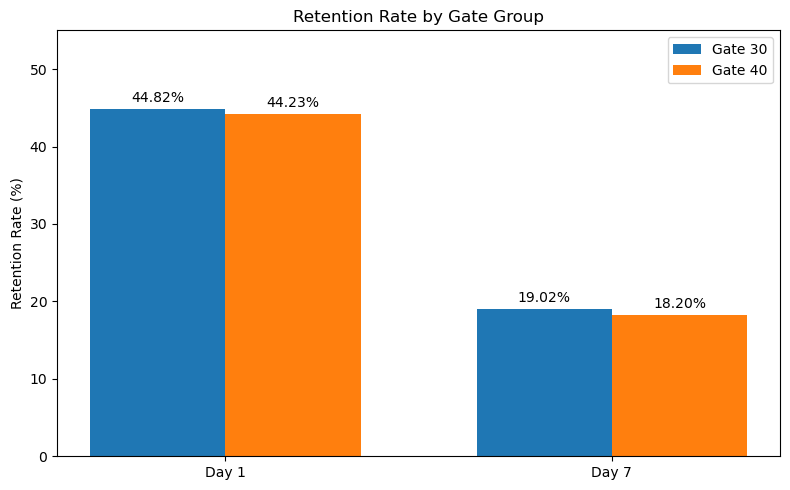

In [13]:
import matplotlib.pyplot as plt
import numpy as np

# 앞에서 계산한 그룹별 리텐션 비율 (%)을 사용
labels = ['Day 1', 'Day 7']
gate_30 = retention_df.loc['gate_30'].tolist()
gate_40 = retention_df.loc['gate_40'].tolist()

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

bars1 = ax.bar(x - width/2, gate_30, width, label='Gate 30')
bars2 = ax.bar(x + width/2, gate_40, width, label='Gate 40')

# 막대 위에 실제 리텐션 표시
ax.bar_label(bars1, fmt='%.2f%%', padding=3)
ax.bar_label(bars2, fmt='%.2f%%', padding=3)

ax.set_ylabel('Retention Rate (%)')
ax.set_title('Retention Rate by Gate Group')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 55)
ax.legend()

plt.tight_layout()
plt.show()


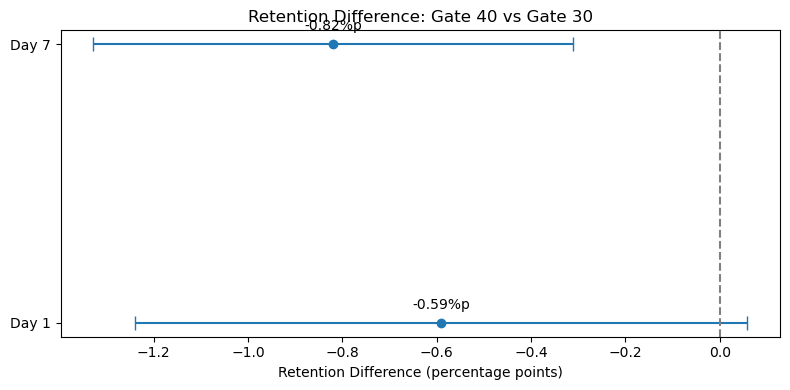

In [14]:
import matplotlib.pyplot as plt

# 각 점(추정 차이)에서 신뢰구간의 양 끝까지 거리 계산
lower_error = result_df['diff'] - result_df['ci_low']
upper_error = result_df['ci_high'] - result_df['diff']

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(
    x=result_df['diff'],
    y=result_df['metric'],
    xerr=[lower_error, upper_error],
    fmt='o',
    capsize=5
)

# 0%p 기준선: 신뢰구간이 0을 포함하면 5% 유의수준에서 차이가 유의하지 않음
ax.axvline(x=0, color='gray', linestyle='--')
ax.set_xlabel('Retention Difference (percentage points)')
ax.set_title('Retention Difference: Gate 40 vs Gate 30')

# Day 1과 Day 7의 차이를 모두 자동으로 표시
for _, row in result_df.iterrows():
    ax.annotate(
        f"{row['diff']:+.2f}%p",
        xy=(row['diff'], row['metric']),
        xytext=(0, 10),
        textcoords='offset points',
        ha='center'
    )

fig.tight_layout()
plt.show()

## 최종 결론 및 비즈니스 제안

### 분석 결과
- **1일 리텐션:** Gate 40이 Gate 30보다 약 **0.59%p 낮게 관측**되었으나, 5% 유의수준에서 통계적으로 유의한 차이를 확인하지 못했다(p ≈ 0.0744).
- **7일 리텐션:** Gate 40이 Gate 30보다 약 **0.82%p 낮게 관측**되었으며, 통계적으로 유의한 차이가 나타났다(p ≈ 0.00155).

### 실험의 한계
- 원본 실험은 사용자를 Gate 30과 Gate 40에 무작위 배정한 것으로 설명되지만, **정확한 목표 배정 비율은 확인되지 않았다.**
- **50:50 배정을 가정한** SRM 검정에서 p-value는 약 **0.0086**으로 나타났다. 이는 해당 가정하에서 기대 배정 비율과 관측 비율 사이에 통계적으로 유의한 차이가 있음을 뜻한다.
- 다만 실제 배정 설정과 데이터 수집 과정에 대한 정보가 부족하므로, **실험 배정 또는 수집 오류가 발생했다고 단정할 수 없다.**
- 따라서 7일 리텐션 차이는 관측된 통계적 결과로 보고하되, 게이트 변경의 **확정적인 인과 효과**로 해석하지 않는다.

### 비즈니스 제안
1. 현재 결과만으로 Gate 40 변경을 확대 적용하지 않는다.
2. 목표 배정 비율, 사용자 할당 로직, 이벤트 수집 및 누락 여부를 확인한다.
3. 실험 신뢰성을 확인한 뒤 재분석하거나 필요하면 재실험하여 의사결정한다.